# Formalização do Problema de ML e Regressão Linear

**Projeto:** Análise e Segurança de Agentes de IA, com classificação de intenção em tickets de atendimento ao cliente.

Este notebook tem duas partes:

1. **Formalização do problema de Machine Learning:** pergunta, entrada (X), alvo (y), classes de intenção e distribuição das classes.
2. **Regressão linear e análise do modelo:** experimento com uma variável numérica derivada do texto, avaliado com R², RMSE, Residual Plot e Q-Q Plot.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("../data/customer_support_tickets.csv")
print("Dimensões:", df.shape)

Dimensões: (8469, 17)


# Parte 1: Formalização do problema de Machine Learning

## 1.1 Pergunta do projeto

> **Dado o texto de uma mensagem de atendimento ao cliente, qual é a intenção do usuário?**

O objetivo é que, ao receber uma mensagem pela rota `/predict`, o sistema devolva a intenção do cliente (por exemplo, pedir reembolso ou cancelar um produto), permitindo encaminhar ou automatizar o atendimento.

## 1.2 Definição formal

| Elemento | Definição |
|---|---|
| **Entrada (X)** | Texto da mensagem do cliente: `Ticket Subject` (assunto) concatenado com `Ticket Description` (descrição). É uma variável textual não estruturada, que será convertida em representação numérica (por exemplo TF-IDF ou embeddings) na etapa de modelagem. |
| **Alvo (y)** | `Ticket Type`: a intenção do cliente, uma variável **categórica** com 5 classes. |
| **Tipo de problema** | Classificação supervisionada **multiclasse** e de **rótulo único** (cada ticket pertence a exatamente uma intenção). |
| **Função a aprender** | f(texto) → uma classe de intenção |
| **Métricas adequadas** | Acurácia, precisão, recall e F1 (macro), além da matriz de confusão. |

A coluna `Ticket Type` serve como rótulo verdadeiro (*ground truth*) para o treinamento supervisionado.

In [2]:
# Montagem de X e y
df["texto"] = df["Ticket Subject"] + ". " + df["Ticket Description"]

X = df["texto"]
y = df["Ticket Type"]

print("Valores ausentes em X (assunto/descrição):",
      df[["Ticket Subject", "Ticket Description"]].isna().sum().sum())
print("Valores ausentes em y (Ticket Type):", y.isna().sum())

exemplos = df.sample(3, random_state=RANDOM_STATE)
for _, linha in exemplos.iterrows():
    print("\n--- Exemplo ---")
    print("X:", linha["texto"][:300].replace("\n", " "))
    print("y:", linha["Ticket Type"])

Valores ausentes em X (assunto/descrição): 0
Valores ausentes em y (Ticket Type): 0

--- Exemplo ---
X: Product setup. I'm having an issue with the {product_purchased}. Please assist. I'm using xda-developer for something different. If there are issues with the {product_purchased} it's likely you are not using the I've tried clearing the cache and data for the {product_purchased} app, but the issue pe
y: Refund request

--- Exemplo ---
X: Battery life. I'm having trouble connecting my {product_purchased} to my home Wi-Fi network. It doesn't detect any networks, although other devices are connecting fine. What can be done to resolve this issue? I will refer to this issue I've checked for any available software updates for my {product_
y: Product inquiry

--- Exemplo ---
X: Refund request. I'm having an issue with the {product_purchased}. Please assist.  Please give credit to: @joeyclay I'm concerned about the security of my {product_purchased} and would like to ensure that my data is sa

## 1.3 Classes de intenção

O modelo deverá prever **5 classes**, que correspondem aos valores distintos de `Ticket Type`:

| Classe | Significado da intenção |
|---|---|
| `Billing inquiry` | Dúvida ou problema relacionado a cobrança e faturamento |
| `Cancellation request` | Pedido de cancelamento de produto ou serviço |
| `Product inquiry` | Dúvida ou pedido de informação sobre um produto |
| `Refund request` | Pedido de reembolso |
| `Technical issue` | Problema técnico ou de funcionamento do produto |

O significado de cada classe foi inferido pelos nomes do dataset, já que o Kaggle não fornece uma descrição formal das categorias.

In [3]:
classes = sorted(y.unique())
print(f"Número de classes: {len(classes)}")
print(classes)

Número de classes: 5
['Billing inquiry', 'Cancellation request', 'Product inquiry', 'Refund request', 'Technical issue']


## 1.4 Distribuição das classes

A tabela e o gráfico abaixo mostram a quantidade e o percentual de exemplos de cada classe.

In [4]:
dist = (
    y.value_counts()
    .rename_axis("Classe")
    .reset_index(name="Quantidade")
)
dist["Percentual (%)"] = (dist["Quantidade"] / len(df) * 100).round(2)

total = pd.DataFrame({"Classe": ["TOTAL"],
                      "Quantidade": [dist["Quantidade"].sum()],
                      "Percentual (%)": [dist["Percentual (%)"].sum().round(2)]})
pd.concat([dist, total], ignore_index=True)

,Classe,Quantidade,Percentual (%)
0,Refund request,1752,20.69
1,Technical issue,1747,20.63
2,Cancellation request,1695,20.01
3,Product inquiry,1641,19.38
4,Billing inquiry,1634,19.29
5,TOTAL,8469,100.00


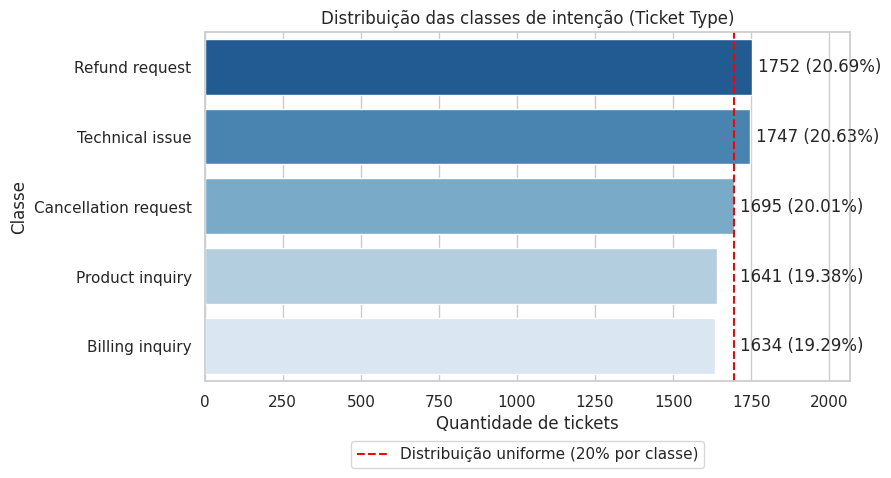

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=dist, x="Quantidade", y="Classe", hue="Classe",
            palette="Blues_r", legend=False, ax=ax)

# linha de referência: distribuição uniforme (20% cada)
ax.axvline(len(df) / len(classes), color="red", linestyle="--",
           label="Distribuição uniforme (20% por classe)")

for i, row in dist.iterrows():
    ax.text(max(row["Quantidade"], len(df) / len(classes)) + 20, i,
            f'{row["Quantidade"]} ({row["Percentual (%)"]}%)', va="center")

ax.set_xlim(0, dist["Quantidade"].max() * 1.18)
ax.set_title("Distribuição das classes de intenção (Ticket Type)")
ax.set_xlabel("Quantidade de tickets")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

### Existe desbalanceamento?

Para responder com números, medimos a razão entre a maior e a menor classe e aplicamos um teste qui-quadrado de aderência contra a distribuição uniforme (H0: todas as classes têm a mesma frequência).

In [6]:
contagens = dist["Quantidade"].values
razao = contagens.max() / contagens.min()
chi2, p = stats.chisquare(contagens)   # esperado = uniforme

print(f"Classe mais frequente : {dist.iloc[0]['Classe']} ({contagens.max()})")
print(f"Classe menos frequente: {dist.iloc[-1]['Classe']} ({contagens.min()})")
print(f"Razão maior/menor     : {razao:.3f}")
print(f"Diferença em pontos percentuais: "
      f"{dist['Percentual (%)'].max() - dist['Percentual (%)'].min():.2f} p.p.")
print(f"Qui-quadrado = {chi2:.2f} | p-valor = {p:.4f}")
print(f"Acurácia de um classificador que chuta uma classe qualquer (baseline): {1/len(classes):.0%}")
print(f"Acurácia de um classificador que sempre prevê a classe majoritária  : {contagens.max()/contagens.sum():.2%}")

Classe mais frequente : Refund request (1752)
Classe menos frequente: Billing inquiry (1634)
Razão maior/menor     : 1.072
Diferença em pontos percentuais: 1.40 p.p.
Qui-quadrado = 7.43 | p-valor = 0.1149
Acurácia de um classificador que chuta uma classe qualquer (baseline): 20%
Acurácia de um classificador que sempre prevê a classe majoritária  : 20.69%


**Conclusão:** **não há classes significativamente mais frequentes que outras.** As 5 classes ficam entre ≈ 19,3% e ≈ 20,7% do dataset. A razão entre a maior e a menor é ≈ 1,07 e a diferença é de ≈ 1,4 ponto percentual. O teste qui-quadrado não rejeita a hipótese de distribuição uniforme (p > 0,05). O dataset é, na prática, **balanceado**.

Implicações para a modelagem:

- Não é necessário aplicar técnicas de balanceamento (*oversampling*, *undersampling* ou pesos de classe) por causa da distribuição.
- A **acurácia é uma métrica válida**, pois a classe majoritária representa só ≈ 20,7% (o baseline ingênuo acerta cerca de 20%). Ainda assim, vale reportar **F1 macro** e a **matriz de confusão**, para ver o desempenho por classe.
- Usar divisão **estratificada** entre treino e teste (`stratify=y`) mantém as proporções iguais nos dois conjuntos.

## 1.5 Por que é um problema de classificação

- **A saída é uma categoria, não uma quantidade.** O modelo precisa escolher entre 5 intenções discretas e mutuamente exclusivas (reembolso, cancelamento, problema técnico, etc.). Não existe valor intermediário: um ticket não é "meio reembolso e meio cancelamento".
- **As classes não têm ordem nem distância.** Não faz sentido dizer que `Billing inquiry` é "menor" ou "mais próxima" de `Cancellation request` do que de `Technical issue`. São rótulos nominais.
- **O rótulo já existe no dataset.** Como `Ticket Type` está anotado em todos os exemplos, é um caso típico de aprendizado supervisionado com alvo categórico.
- **O uso final exige uma decisão.** A rota `/predict` precisa devolver uma intenção para encaminhar o ticket, e as métricas relevantes (acurácia, F1, matriz de confusão) medem acertos e erros de classe.

## 1.6 Por que a regressão linear não é adequada para prever as intenções diretamente

1. **Saída contínua versus saída categórica.** A regressão linear produz um número real qualquer (por exemplo 2,37), e não uma das 5 classes.
2. **Codificar as classes como números cria uma ordem falsa.** Para usar regressão seria preciso transformar as classes em 0, 1, 2, 3, 4. Isso impõe uma ordem e uma distância que não existem. O modelo trataria `Technical issue` (4) como "quatro vezes mais" que `Cancellation request` (1) e consideraria `Billing inquiry` (0) mais parecida com `Cancellation request` (1) do que com `Technical issue` (4), apenas pela ordem alfabética dos rótulos.
3. **Previsões sem significado.** Uma previsão de 2,5 cairia entre duas classes sem representar nenhuma delas. Arredondar o resultado seria um remendo, pois o modelo foi otimizado para minimizar erro quadrático e não para separar classes.
4. **Função de perda e métricas inadequadas.** O erro quadrático (base do R² e do RMSE) mede distâncias numéricas, que aqui não têm significado. Classificadores usam perdas como entropia cruzada, que tratam as classes como categorias independentes e produzem probabilidades por classe.
5. **Fronteiras de decisão.** Uma única reta ajustada a rótulos numéricos não consegue separar bem várias classes sem ordem, enquanto modelos de classificação (regressão logística multinomial, Naive Bayes, SVM, redes neurais) foram feitos para isso.

A célula a seguir mostra a codificação numérica que uma regressão exigiria e a ordem arbitrária que ela cria.

In [7]:
le = LabelEncoder()
codigos = le.fit_transform(y)

pd.DataFrame({"Classe": le.classes_,
              "Código numérico": range(len(le.classes_))})

,Classe,Código numérico
0,Billing inquiry,0
1,Cancellation request,1
2,Product inquiry,2
3,Refund request,3
4,Technical issue,4


Os códigos seguem apenas a **ordem alfabética**, sem relação com o significado das intenções. Se uma regressão linear prever, por exemplo, 0,5, esse valor fica "entre" `Billing inquiry` e `Cancellation request`, o que não corresponde a uma intenção real.

Por isso, o problema principal do projeto será tratado com **modelos de classificação** sobre uma representação numérica do texto (TF-IDF ou embeddings). A regressão linear fica restrita, nesta atividade, ao exercício da Parte 2, em que prevemos uma variável numérica derivada do texto.

---

# Parte 2: Regressão linear e análise do modelo

**Objetivo:** treinar um modelo de regressão linear com os dados do projeto, avaliar com **R²** e **RMSE** e analisar os erros com **Residual Plot** e **Q-Q Plot**.

Como o problema principal é de *classificação* (Parte 1), aqui o alvo é uma variável **numérica** derivada do texto: a quantidade de palavras da descrição.

## 2.1 Definição do problema

| Item | Escolha |
|---|---|
| **Variável alvo (y)** | `Word Count`: quantidade de palavras de `Ticket Description` |
| **Variáveis de entrada (X)** | `Ticket Type`, `Ticket Subject`, `Ticket Priority`, `Ticket Channel`, `Product Purchased`, `Customer Gender` (categóricas) e `Customer Age` (numérica) |

**Por que essa variável alvo?** É numérica, vem direto do texto que será enviado à rota `/predict` e é fácil de interpretar.

**Por que essas entradas?** São os metadados do ticket, sem nenhuma coluna derivada da própria descrição. Assim evitamos *vazamento de dados* (data leakage): prever o número de palavras usando contagens calculadas a partir do mesmo texto seria trivial e não ensinaria nada.

In [8]:
# Variável alvo: quantidade de palavras da descrição
df["Word Count"] = df["Ticket Description"].str.split().str.len()

df["Word Count"].describe()

count    8469.000000
mean       46.467352
std         8.461730
min        21.000000
25%        43.000000
50%        49.000000
75%        52.000000
max        63.000000
Name: Word Count, dtype: float64

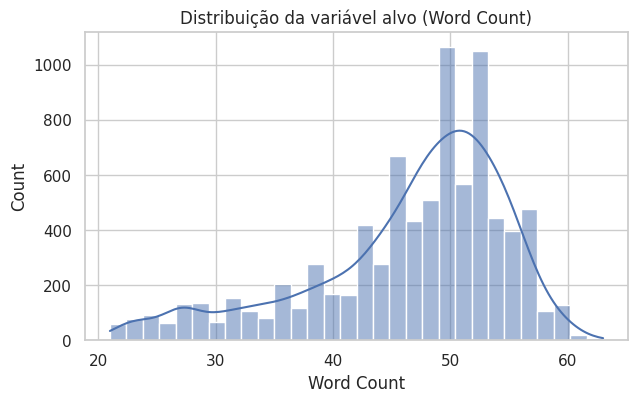

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["Word Count"], bins=30, kde=True, ax=ax)
ax.set_title("Distribuição da variável alvo (Word Count)")
plt.show()

## 2.2 Exploração rápida: as entradas têm relação com o alvo?

Antes de treinar, vale checar se as variáveis de entrada mudam a média do alvo. Usamos ANOVA para as categóricas e correlação de Pearson para a idade.

In [10]:
cat_features = ["Ticket Type", "Ticket Subject", "Ticket Priority",
                "Ticket Channel", "Product Purchased", "Customer Gender"]
num_features = ["Customer Age"]

rows = []
for col in cat_features:
    grupos = [g["Word Count"].values for _, g in df.groupby(col)]
    medias = df.groupby(col)["Word Count"].mean()
    rows.append({"variável": col,
                 "menor média": round(medias.min(), 2),
                 "maior média": round(medias.max(), 2),
                 "p-valor (ANOVA)": round(stats.f_oneway(*grupos).pvalue, 4)})

r, p = stats.pearsonr(df["Customer Age"], df["Word Count"])
rows.append({"variável": "Customer Age (Pearson)", "menor média": np.nan,
             "maior média": np.nan, "p-valor (ANOVA)": round(p, 4)})

pd.DataFrame(rows)

,variável,menor média,maior média,p-valor (ANOVA)
0,Ticket Type,46.18,46.72,0.2442
1,Ticket Subject,45.99,46.95,0.9725
2,Ticket Priority,46.15,46.84,0.0657
3,Ticket Channel,46.25,46.64,0.3197
4,Product Purchased,45.20,48.39,0.0316
5,Customer Gender,46.38,46.56,0.7186
6,Customer Age (Pearson),NaN,NaN,0.6138


## 2.3 Treino e teste

Separamos 80% para treino e 20% para teste. O pré-processamento (one-hot nas categóricas e padronização da idade) fica dentro de um `Pipeline`, ajustado só no treino, para não vazar informação do teste.

In [11]:
X = df[cat_features + num_features]
y = df["Word Count"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("num", StandardScaler(), num_features),
])

model = Pipeline([
    ("preprocess", preprocess),
    ("regressor", LinearRegression()),
])

model.fit(X_train, y_train)

print(f"Treino: {len(X_train)} amostras | Teste: {len(X_test)} amostras")

Treino: 6775 amostras | Teste: 1694 amostras


## 2.4 Métricas: R² e RMSE

Para dar contexto aos números, comparamos com um **baseline** que sempre prevê a média do treino. Esse baseline tem R² ≈ 0 por definição, e seu RMSE é quase igual ao desvio padrão do alvo.

In [12]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Baseline: sempre prever a média do treino
y_base = np.full_like(y_test, y_train.mean(), dtype=float)

def rmse(y_true, y_hat):
    return np.sqrt(mean_squared_error(y_true, y_hat))

resultados = pd.DataFrame({
    "R²":   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test), r2_score(y_test, y_base)],
    "RMSE": [rmse(y_train, y_pred_train),     rmse(y_test, y_pred_test),     rmse(y_test, y_base)],
}, index=["Regressão (treino)", "Regressão (teste)", "Baseline (média, teste)"])

print(f"Desvio padrão do alvo no teste: {y_test.std():.2f} palavras")
resultados.round(4)

Desvio padrão do alvo no teste: 8.72 palavras


,R²,RMSE
Regressão (treino),0.0113,8.3487
Regressão (teste),-0.0053,8.7366
"Baseline (média, teste)",-0.0009,8.7172


## 2.5 Análise dos resíduos

Resíduo = valor real − valor previsto. Em uma regressão linear bem especificada esperamos:

- **Residual Plot:** pontos espalhados aleatoriamente em torno de 0, sem curvas e sem funil (variância constante, ou *homocedasticidade*).
- **Q-Q Plot:** pontos sobre a diagonal, indicando resíduos aproximadamente normais.

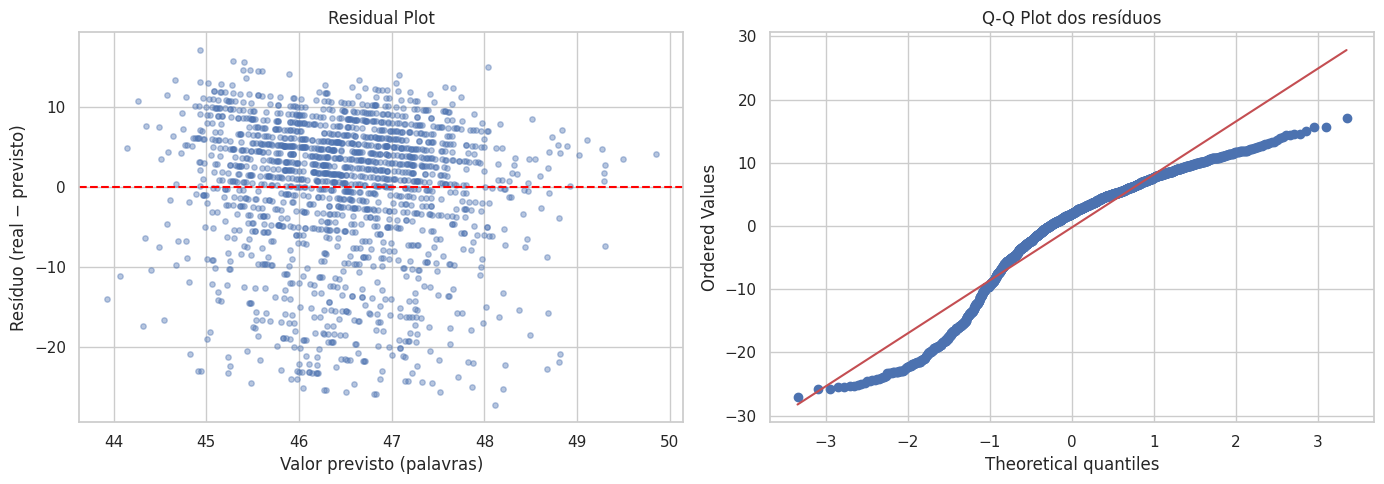

In [13]:
residuos = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residual Plot
axes[0].scatter(y_pred_test, residuos, alpha=0.4, s=15)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Valor previsto (palavras)")
axes[0].set_ylabel("Resíduo (real − previsto)")
axes[0].set_title("Residual Plot")

# Q-Q Plot
stats.probplot(residuos, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot dos resíduos")

plt.tight_layout()
plt.show()

In [14]:
print(f"Média dos resíduos : {residuos.mean():.3f}")
print(f"Desvio padrão      : {residuos.std():.3f}")
print(f"Assimetria (skew)  : {stats.skew(residuos):.3f}")
print(f"Curtose (excesso)  : {stats.kurtosis(residuos):.3f}")
print(f"Resíduo mín / máx  : {residuos.min():.1f} / {residuos.max():.1f}")

Média dos resíduos : -0.214
Desvio padrão      : 8.737
Assimetria (skew)  : -1.000
Curtose (excesso)  : 0.387
Resíduo mín / máx  : -27.1 / 17.1


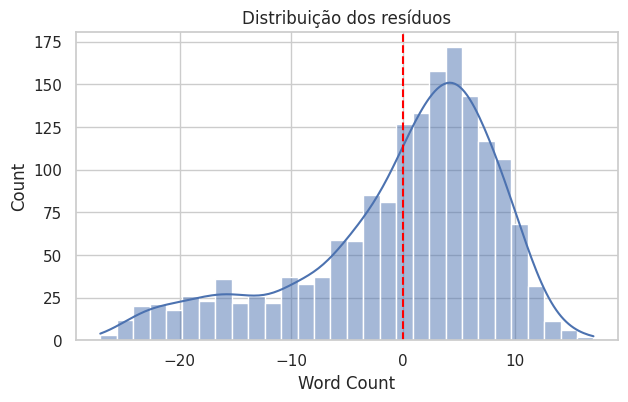

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(residuos, bins=30, kde=True, ax=ax)
ax.axvline(0, color="red", linestyle="--")
ax.set_title("Distribuição dos resíduos")
plt.show()

## 2.6 Documentação do experimento

> **Atenção:** confira os números abaixo com a saída das células anteriores. Se você mudar `RANDOM_STATE` ou as variáveis, os valores mudam.

### 2.6.1 Variável alvo e variáveis de entrada

- **Alvo:** `Word Count`, a quantidade de palavras da descrição do ticket (média ≈ 46,5 e desvio padrão ≈ 8,5 palavras).
- **Entradas:** `Ticket Type`, `Ticket Subject`, `Ticket Priority`, `Ticket Channel`, `Product Purchased`, `Customer Gender` e `Customer Age`.
- As colunas de texto foram usadas só para construir o alvo. Nenhuma entrada foi derivada da descrição, para evitar vazamento.

### 2.6.2 Significado de R² e RMSE

- **R²** mede a fração da variância do alvo explicada pelo modelo. 1 significa previsão perfeita, 0 significa que o modelo não é melhor que prever sempre a média, e valores negativos significam que é pior que a média.
- **RMSE** é o erro médio quadrático, na mesma unidade do alvo (palavras). Representa o erro típico das previsões, com penalização maior para erros grandes.

**Resultado obtido:** R² ≈ −0,005 e RMSE ≈ 8,74 palavras no teste. O RMSE é praticamente igual ao desvio padrão do alvo (≈ 8,72), e o R² ficou colado em zero. Ou seja, **o modelo não é melhor do que prever sempre a média**: as variáveis de entrada não explicam o tamanho da descrição.

### 2.6.3 Limitações identificadas

1. **Ausência de sinal preditivo.** A ANOVA e a correlação (seção 2) já indicavam que o tamanho do texto praticamente não varia entre tipos, prioridades, canais ou idades. A única exceção é `Product Purchased` (p ≈ 0,03), com um efeito pequeno demais para melhorar o modelo. O modelo só confirmou o que a exploração mostrava.
2. **Previsões concentradas em uma faixa estreita.** As previsões variam só entre ≈ 44 e 50 palavras, enquanto o alvo vai de 21 a 63. O modelo prevê quase sempre um valor próximo da média, e por isso os resíduos têm praticamente a mesma dispersão do alvo original (desvio padrão ≈ 8,7). O Residual Plot não mostra curva nem funil (não há sinal de não linearidade ou heterocedasticidade), mas isso não indica bom ajuste: é só consequência de o modelo não ter aprendido nada.
3. **Resíduos não normais.** O Q-Q Plot tem formato de S, e os resíduos têm assimetria negativa (≈ −1,0): há uma cauda longa de textos bem mais curtos que o previsto (resíduos até ≈ −27) e uma cauda superior limitada (máximo ≈ +17). A suposição de normalidade dos erros não é satisfeita, o que enfraquece intervalos de confiança e testes de significância dos coeficientes (as previsões pontuais continuam calculáveis).
4. **Leve sobreajuste.** O R² de treino (≈ 0,011) é um pouco maior que o de teste (≈ −0,005): o one-hot cria muitas colunas e o modelo ajusta um pouco de ruído do treino.
5. **Natureza sintética do dataset.** As descrições são geradas a partir de templates (todas contêm o marcador `{product_purchased}`) e os metadados parecem sorteados de forma independente. Isso explica a falta de relação entre as colunas.
6. **Alvo pouco relevante para o negócio.** Saber quantas palavras um ticket terá não ajuda diretamente em nenhuma decisão do atendimento.

### 2.6.4 Por que a regressão não representa o problema de classificação de intenções

- O problema principal tem **saída categórica** (`Ticket Type`: reembolso, cancelamento, problema técnico, etc.). A regressão prevê uma **quantidade contínua**, e os dois problemas usam métricas diferentes (acurácia, precisão, recall e F1 contra R² e RMSE).
- O que identifica a intenção é o **conteúdo semântico** do texto (quais palavras e que significado), enquanto o tamanho do texto é só uma propriedade superficial. Textos de intenções diferentes podem ter o mesmo tamanho.
- Prever o número de palavras **não passa por nenhuma etapa de interpretação da intenção**. Mesmo que o R² fosse alto, o modelo não saberia dizer se o cliente quer um reembolso ou ajuda técnica.
- Rotular classes com números (1, 2, 3...) para usar regressão seria incorreto, porque criaria uma ordem e uma distância que não existem entre intenções. Para esse problema, o caminho correto é um classificador (regressão logística, Naive Bayes, SVM ou modelos de linguagem) sobre representações do texto, como TF-IDF ou embeddings.